# Proyecto MA4703 Control Óptimo — Avance: Objetivos 4, 5 y 6
## Control estocástico del modelo de Black-Scholes (problema de Merton)

* Profesor: Héctor Ramírez.
* Auxiliares: Hernán Torres, Diego Morales.
* Ayudante: Fraick Reyes.
* Integrantes: Bonnie Lagos, Javier Cruz.

**Objetivo de este avance.** Completar lo que el reporte de avances dejó pendiente en la parte de programación dinámica:

* **Objetivo 5:** caracterizar el control óptimo resolviendo **numéricamente** la ecuación HJB, sin usar la fórmula de Merton, y comparar con $(\Pi^*,\nu)$.
* **Objetivo 4:** ver numéricamente la existencia del control óptimo: la iteración de políticas construye controles admisibles cuyo valor sube hasta $V$, y la condición $\nu>0$ separa los casos con y sin óptimo.
* **Objetivo 6:** estudiar qué pasa al **restringir los controles admisibles**: fracción acotada $\Pi_t\in[\Pi_{\min},\Pi_{\max}]$, y controles markovianos frente a no markovianos.

Usamos lo demostrado en el reporte de avances (HJB, solución explícita y su optimalidad) y la fórmula exacta de $J$ para estrategias proporcionales (Prop. 2 del avance 2).

**Referencias.** [KS] Karatzas–Shreve, *Brownian Motion and Stochastic Calculus*; [R] Ross, *Stochastic Control in Continuous Time*; [KD] Kushner–Dupuis, *Numerical Methods for Stochastic Control Problems in Continuous Time*; [CRRA] documento teórico del proyecto, *El problema de Merton con utilidad CRRA*.

In [1]:
import Pkg; Pkg.add("Plots")   # LinearAlgebra, Statistics, Random y Printf vienen incluidos en Julia
using Plots, LinearAlgebra, Statistics, Random, Printf

# estilo de los gráficos para el póster: letras grandes y líneas gruesas
default(size=(800, 540), titlefontsize=18, guidefontsize=16, tickfontsize=13, legendfontsize=12,
        linewidth=3, markersize=7, framestyle=:box, gridalpha=0.15, margin=6Plots.mm, dpi=150,
        foreground_color_legend=nothing)
mkpath("figuras_poster");  # cada gráfico se guarda también solo, en PNG de 300 dpi

     Project No packages added to or removed from `C:\Users\bonni\.julia\environments\v1.12\Project.toml`
    Manifest No packages added to or removed from `C:\Users\bonni\.julia\environments\v1.12\Manifest.toml`


## 1. Problema y solución exacta (recordatorio)

Con $U(c)=\frac{c^{1-\eta}-1}{1-\eta}$, la función valor resuelve la HJB
$$
\gamma V=\sup_{\Pi\in\mathbb R,\ c\ge0}\Big\{U(c)+\big[(r+\Pi(\mu-r))x-c\big]V'+\tfrac12\sigma^2\Pi^2x^2V''\Big\},
$$
y si $\nu>0$ la solución es $V(x)=\frac{1}{1-\eta}\big(\nu^{-\eta}x^{1-\eta}-\frac1\gamma\big)$, con $\Pi^*=\frac{\mu-r}{\eta\sigma^2}$ y $C^*=\nu X$. Para una estrategia proporcional $(\bar\pi,\bar cX)$ con $\eta>1$ el valor exacto es (Prop. 2 del avance 2)
$$
J(x;\bar\pi,\bar c)=\frac{(\bar cx)^{1-\eta}}{(1-\eta)\kappa}-\frac{1}{(1-\eta)\gamma},\qquad \kappa(\bar\pi,\bar c)=\gamma-(1-\eta)\Big(r+\bar\pi(\mu-r)-\bar c-\tfrac\eta2\sigma^2\bar\pi^2\Big)>0.
$$
Como en este avance cambiamos $\eta$, escribimos todo como funciones de los parámetros `P`.

In [2]:
# parámetros del modelo (los mismos de los avances anteriores)
const par = (r = 0.03, mu = 0.08, sigma = 0.20, eta = 2.0, gamma = 0.05, x0 = 100.0)

U(c; P=par) = (c^(1 - P.eta) - 1)/(1 - P.eta)                               # utilidad CRRA (eta != 1)
theta(P=par)  = (P.mu - P.r)/P.sigma                                         # precio de mercado del riesgo
Pistar(P=par) = (P.mu - P.r)/(P.eta*P.sigma^2)                               # fracción de Merton
nustar(P=par) = (P.gamma - (1 - P.eta)*(P.r + theta(P)^2/(2*P.eta)))/P.eta  # tasa óptima de consumo
V(x; P=par) = (nustar(P)^(-P.eta)*x^(1 - P.eta) - 1/P.gamma)/(1 - P.eta)    # función valor exacta

# valor exacto de la estrategia proporcional (Pi, c X), eta > 1 (Prop. 2 del avance 2)
kappa(Pi, c; P=par) = P.gamma - (1 - P.eta)*(P.r + Pi*(P.mu - P.r) - c - 0.5*P.eta*P.sigma^2*Pi^2)
Jexacto(Pi, c; P=par, x=P.x0) = kappa(Pi, c; P=P) > 0 ? ((c*x)^(1 - P.eta)/kappa(Pi, c; P=P) - 1/P.gamma)/(1 - P.eta) : -Inf

# capital equivalente: V(xCE) = J
xCE(J; P=par) = isfinite(J) ? (nustar(P)^P.eta*((1 - P.eta)*J + 1/P.gamma))^(1/(1 - P.eta)) : 0.0

@printf("Pi* = %.4f   nu = %.6f   V(x0) = %.6f\n", Pistar(), nustar(), V(par.x0))

Pi* = 0.6250   nu = 0.047813   V(x0) = 15.625614


## 2. La HJB en coordenada logarítmica y la condición de borde

**Cambio de variable.** El capital vive en varias escalas (de 1 a 10 000), así que trabajamos en $y=\log x$ con $W(y)=V(e^y)$. Como $V'=e^{-y}W'$ y $V''=e^{-2y}(W''-W')$, y escribiendo el consumo como tasa $e=c/x$, la HJB queda
$$
\gamma W=\sup_{\Pi\in[\Pi_{\min},\Pi_{\max}],\ e\ge0}\Big\{U(e\,e^{y})+b(\Pi,e)\,W'+a(\Pi)\,W''\Big\},\qquad b=r+\Pi(\mu-r)-e-\tfrac12\sigma^2\Pi^2,\quad a=\tfrac12\sigma^2\Pi^2. \tag{HJB-log}
$$
La difusión $a$ ya no depende del estado, y una malla uniforme en $y$ es geométrica en $x$. Dejamos el intervalo de la fracción como parámetro para la Sección 6 ($\Pi_{\min}=-\infty$, $\Pi_{\max}=+\infty$ es el problema sin restricción).

**Proposición 1 (homotecia).** Para todo $\lambda>0$, $V(\lambda x)=\lambda^{1-\eta}V(x)+\frac{\lambda^{1-\eta}-1}{(1-\eta)\gamma}$. En consecuencia
$$
W'(y)=(1-\eta)W(y)+\frac1\gamma,\qquad W''(y)=(1-\eta)W'(y).
$$

*Demostración.* Si $(\Pi,C)$ es admisible desde $x$, entonces $(\Pi,\lambda C)$ es admisible desde $\lambda x$ y su capital es $\lambda X$, porque la ecuación es lineal en $(X,C)$. Como $U(\lambda c)=\lambda^{1-\eta}U(c)+\frac{\lambda^{1-\eta}-1}{1-\eta}$, se tiene $J(\lambda x;\Pi,\lambda C)=\lambda^{1-\eta}J(x;\Pi,C)+\frac{\lambda^{1-\eta}-1}{(1-\eta)\gamma}$, y tomando supremo (la correspondencia $C\leftrightarrow\lambda C$ es biyectiva) se obtiene la igualdad. Derivando en $\lambda=1$ queda $xV'(x)=(1-\eta)V(x)+\frac1\gamma$, que en $y$ es la primera identidad; derivándola se obtiene la segunda. $\blacksquare$

La proposición usa solo la estructura del problema (dinámica lineal y utilidad homogénea), **no** la fórmula de $V$, y sigue valiendo si la fracción se restringe a un intervalo.

**Condición de borde.** En los extremos de la malla faltan vecinos para aproximar $W'$ y $W''$, así que usamos la Proposición 1. Reemplazándola en (HJB-log) para una política fija $(\Pi,e)$ queda
$$
\big[\gamma-(1-\eta)\big(b+(1-\eta)a\big)\big]W=U(e\,e^{y})+\frac{b+(1-\eta)a}{\gamma},
$$
y como $b+(1-\eta)a=r+\Pi(\mu-r)-e-\frac\eta2\sigma^2\Pi^2$, el corchete es exactamente $\kappa(\Pi,e)$: **el valor en el borde es el de mantener para siempre la política proporcional del borde**, $W=J(e^y;\Pi,e)$ (Prop. 2 del avance 2). Así el borde no necesita conocer $V$.

## 3. Esquema numérico: diferencias *upwind* e iteración de políticas

En la malla $y_i=y_1+(i-1)k$, $i=1,\dots,n$, aproximamos $W'$ con diferencias hacia adelante si $b\ge0$ y hacia atrás si $b<0$ (*upwind*), y $W''$ con diferencias centradas. Para una política fija queda el sistema tridiagonal
$$
\Big(\gamma+\frac{b^++b^-}{k}+\frac{2a}{k^2}\Big)W_i-\Big(\frac{b^+}{k}+\frac{a}{k^2}\Big)W_{i+1}-\Big(\frac{b^-}{k}+\frac{a}{k^2}\Big)W_{i-1}=U(e_i\,e^{y_i}),\qquad b^\pm=\max(\pm b,0).
$$
Los coeficientes fuera de la diagonal son $\le0$ y la diagonal domina estrictamente gracias a $\gamma>0$: es una **M-matriz**, así que el sistema tiene solución única y el esquema es **monótono**. Es la aproximación por cadenas de Markov de [KD]: dividiendo por la diagonal, los coeficientes de $W_{i\pm1}$ son las probabilidades de saltar a un nodo vecino multiplicadas por un factor de descuento, y la monotonía es lo que garantiza la convergencia a la solución de la HJB.

**Iteración de políticas (Howard).** Partimos de la política "todo en el banco y consumir los intereses", $\Pi=0$, $e=r$ (el capital queda constante y $\kappa=\gamma>0$), y repetimos:
1. *evaluación:* resolver el sistema lineal para la política actual, lo que da $W^{(m)}$;
2. *mejora:* en cada nodo, maximizar el lado derecho de (HJB-log) con las derivadas de $W^{(m)}$ (diferencias centradas). Las condiciones de primer orden dan
$$
e=\Big(\frac{e^{(1-\eta)y}}{W'}\Big)^{1/\eta},\qquad \Pi=\mathrm{proy}_{[\Pi_{\min},\Pi_{\max}]}\Big(-\frac{(\mu-r)W'}{\sigma^2(W''-W')}\Big),
$$
porque $U$ es cóncava y el término en $\Pi$ es una parábola cóncava cuando $W''<W'$.

**Proposición 2 (Howard).** Si en la mejora se maximiza el lado derecho discreto, los valores son crecientes, $W^{(1)}\le W^{(2)}\le\cdots$, y convergen a la solución del esquema [KD], [CRRA, Lema de Howard]. Cada $W^{(m)}$ es el valor de un control de retroalimentación markoviano admisible, así que el método **construye** controles cada vez mejores. Nosotros usamos las condiciones de primer orden con diferencias centradas, que es más simple; en la Sección 5 se ve que igual los valores crecen.

In [3]:
# Resuelve (HJB-log) en la malla uniforme y, por iteración de políticas (Howard).
# Devuelve W, la política (Pi, e) en cada nodo y el valor en x0 de cada iteración.
function resolver_hjb(y; P=par, Pimin=-5.0, Pimax=5.0, tol=1e-10, maxit=100)
    n = length(y); k = y[2] - y[1]; x = exp.(y)
    i0 = argmin(abs.(x .- P.x0))                       # nodo de x0
    Pi = fill(0.0, n); e = fill(P.r, n)                 # política inicial: banco, consumir los intereses
    W = zeros(n); historial = Float64[]
    for it in 1:maxit
        # 1. evaluación: sistema tridiagonal con upwind
        b = P.r .+ Pi .* (P.mu - P.r) .- e .- 0.5*P.sigma^2 .* Pi.^2
        a = 0.5*P.sigma^2 .* Pi.^2
        bp, bm = max.(b, 0), max.(-b, 0)
        dl = -(bm ./ k .+ a ./ k^2)                     # coeficiente de W[i-1]
        d  = P.gamma .+ (bp .+ bm) ./ k .+ 2a ./ k^2    # coeficiente de W[i]
        du = -(bp ./ k .+ a ./ k^2)                     # coeficiente de W[i+1]
        rhs = U.(e .* x; P=P)
        for i in (1, n)                                 # bordes: Prop. 1 (homotecia)
            dl[i] = 0.0; du[i] = 0.0
            d[i] = kappa(Pi[i], e[i]; P=P)
            rhs[i] = U(e[i]*x[i]; P=P) + (b[i] + (1 - P.eta)*a[i])/P.gamma
        end
        Wn = Tridiagonal(dl[2:n], d, du[1:n-1]) \ rhs
        push!(historial, Wn[i0])
        # 2. mejora: condiciones de primer orden con diferencias centradas
        W1, W2 = similar(Wn), similar(Wn)
        for i in 2:n-1
            W1[i] = (Wn[i+1] - Wn[i-1])/(2k)
            W2[i] = (Wn[i+1] - 2Wn[i] + Wn[i-1])/k^2
        end
        for i in (1, n)                                 # en los bordes, Prop. 1
            W1[i] = (1 - P.eta)*Wn[i] + 1/P.gamma
            W2[i] = (1 - P.eta)*W1[i]
        end
        W1 = max.(W1, 1e-12)                            # V es creciente: W' > 0
        e = (x .^ (1 - P.eta) ./ W1) .^ (1/P.eta)
        den = P.sigma^2 .* (W2 .- W1)
        Pi = [den[i] < 0 ? clamp(-(P.mu - P.r)*W1[i]/den[i], Pimin, Pimax) : Pimax for i in 1:n]
        cambio = maximum(abs.(Wn .- W))/maximum(abs.(Wn))
        W = Wn
        cambio < tol && break
    end
    return (W=W, Pi=Pi, e=e, x=x, historial=historial)
end

resolver_hjb (generic function with 1 method)

## 4. Validación contra la solución exacta (objetivo 5)

Malla en $x\in[1,10^4]$ con $n$ impar, de modo que $x_0=100$ es el nodo central. Medimos el error de los controles en $x\in[5,2000]$ y el error en $V(x_0)$, también en capital equivalente, $x_{CE}(W(x_0))-x_0$, que está en las mismas unidades que el capital.

In [4]:
println("    n  iter  max|Pi - Pi*|  max|e - nu|  W(x0) - V(x0)  xCE - x0  tiempo")
ns = [101, 201, 401, 801, 1601, 3201]; errV = Float64[]
for n in ns
    y = collect(range(log(1.0), log(1e4), length=n))
    t = @elapsed s = resolver_hjb(y)
    I = (s.x .>= 5) .& (s.x .<= 2000); i0 = (n + 1) ÷ 2
    push!(errV, s.W[i0] - V(par.x0))
    @printf("%5d %5d %14.2e %12.2e %14.2e %9.4f %6.2fs\n", n, length(s.historial),
            maximum(abs.(s.Pi[I] .- Pistar())), maximum(abs.(s.e[I] .- nustar())), errV[end], xCE(s.W[i0]) - par.x0, t)
end
println("orden de convergencia en V(x0): ", join([@sprintf("%.2f", log2(errV[j]/errV[j+1])) for j in 1:length(ns)-1], ", "))

    n  iter  max|Pi - Pi*|  max|e - nu|  W(x0) - V(x0)  xCE - x0  tiempo
  101     8       6.55e-04     1.67e-04      -2.43e-02   -0.5523   2.26s
  201     8       2.80e-04     7.46e-05      -1.20e-02   -0.2730   0.00s
  401     7       1.24e-04     3.50e-05      -5.95e-03   -0.1359   0.00s
  801     7       5.79e-05     1.70e-05      -2.97e-03   -0.0678   0.00s
 1601     7       2.80e-05     8.34e-06      -1.48e-03   -0.0339   0.01s
 3201     6       1.37e-05     4.13e-06      -7.41e-04   -0.0169   0.01s
orden de convergencia en V(x0): 1.02, 1.01, 1.00, 1.00, 1.00


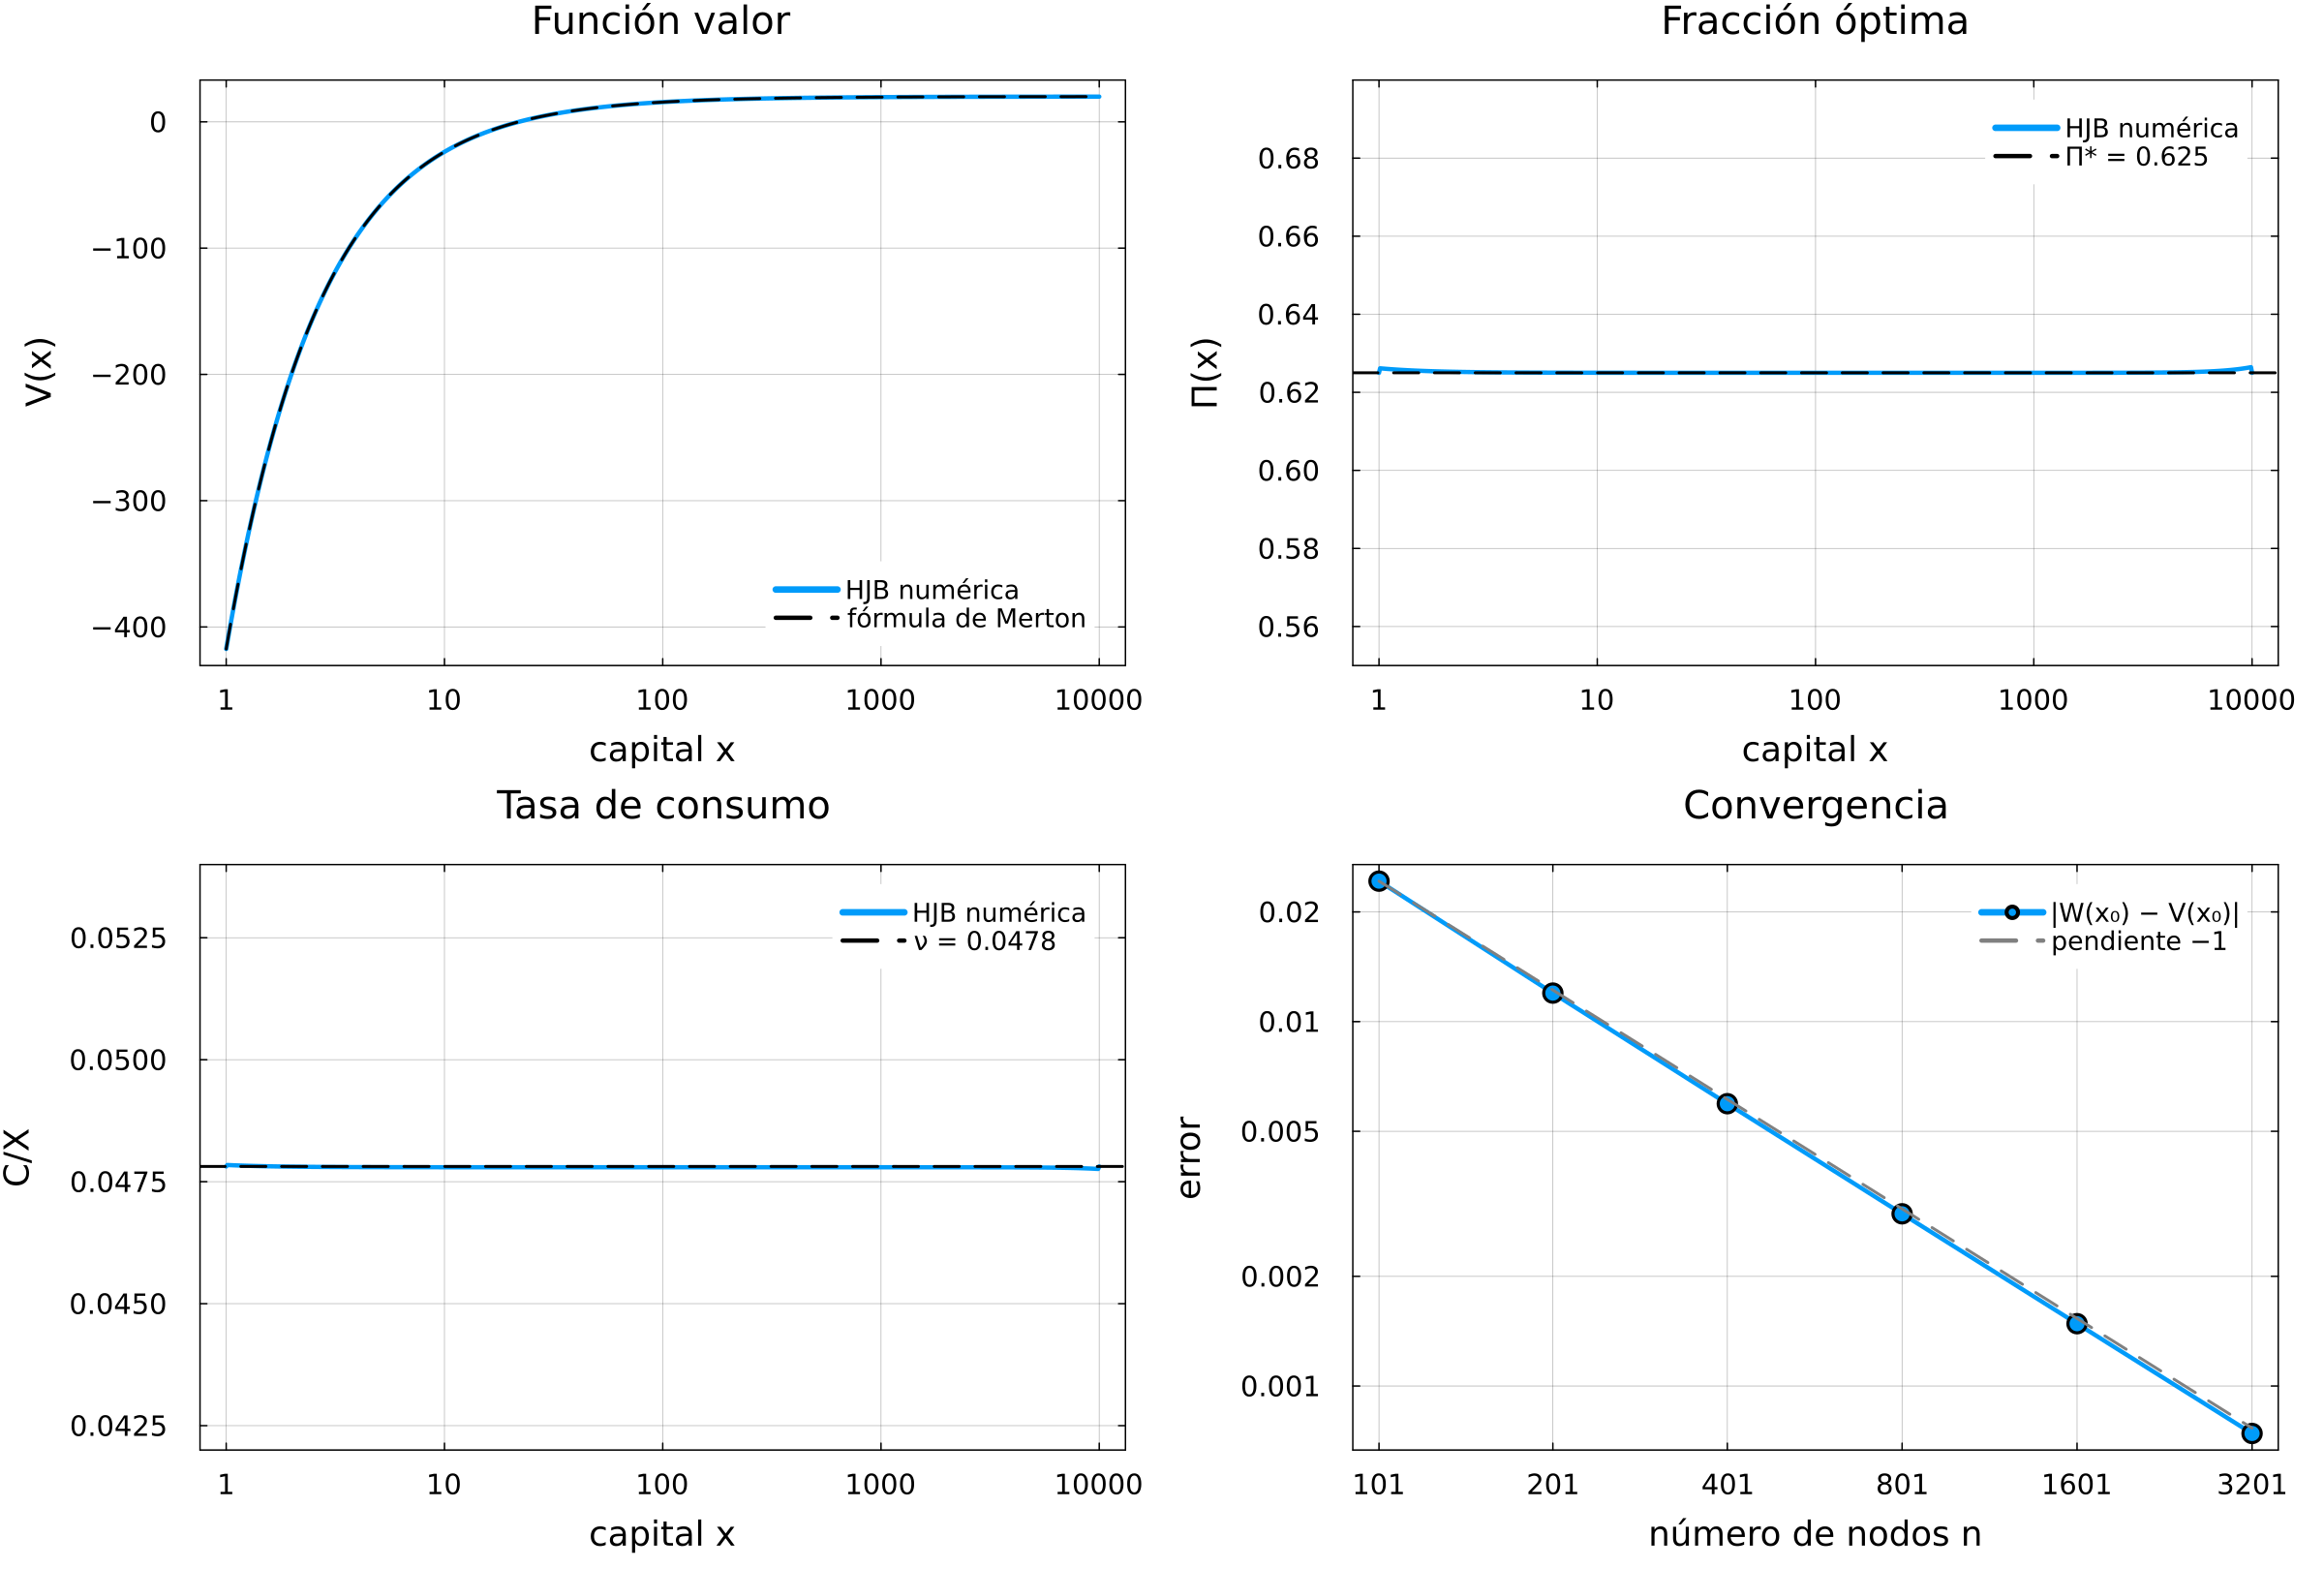

In [5]:
y = collect(range(log(1.0), log(1e4), length=801)); s = resolver_hjb(y)
ejex = ([1, 10, 100, 1000, 10000], ["1", "10", "100", "1000", "10000"])   # marcas del eje x en escala log
p1 = plot(s.x, s.W, xscale=:log10, label="HJB numérica", title="Función valor", xlabel="capital x", ylabel="V(x)",
          legend=:bottomright, xticks=ejex)
plot!(p1, s.x, V.(s.x), ls=:dash, color=:black, lw=2, label="fórmula de Merton")
p2 = plot(s.x, s.Pi, xscale=:log10, label="HJB numérica", title="Fracción óptima", xlabel="capital x", ylabel="Π(x)",
          ylims=(0.55, 0.7), xticks=ejex)
hline!(p2, [Pistar()], ls=:dash, color=:black, lw=2, label="Π* = 0.625")
p3 = plot(s.x, s.e, xscale=:log10, label="HJB numérica", title="Tasa de consumo", xlabel="capital x", ylabel="C/X",
          ylims=(0.042, 0.054), xticks=ejex)
hline!(p3, [nustar()], ls=:dash, color=:black, lw=2, label="ν = 0.0478")
p4 = plot(ns, abs.(errV), xscale=:log10, yscale=:log10, marker=:circle, label="|W(x₀) − V(x₀)|",
          title="Convergencia", xlabel="número de nodos n", ylabel="error", xticks=(ns, string.(ns)),
          yticks=([1e-3, 2e-3, 5e-3, 1e-2, 2e-2], ["0.001", "0.002", "0.005", "0.01", "0.02"]))
plot!(p4, ns, abs(errV[1]) .* ns[1] ./ ns, ls=:dash, color=:gray, lw=2, label="pendiente −1")
for (p, nombre) in [(p1, "valor"), (p2, "fraccion"), (p3, "consumo"), (p4, "convergencia")]
    savefig(plot(p, dpi=300), "figuras_poster/hjb_$nombre.png")
end

# para el reporte, los cuatro paneles en una fila con letras más chicas
fig = plot(p1, p2, p3, p4, layout=(1, 4), size=(1150, 300), titlefontsize=10, guidefontsize=9, tickfontsize=7,
           legendfontsize=7, bottom_margin=7Plots.mm, left_margin=3Plots.mm)
mkpath("figuras_final"); savefig(fig, "figuras_final/hjb_merton.pdf")
plot(p1, p2, p3, p4, layout=(2, 2), size=(1600, 1080))

El esquema converge con **orden 1** en $V(x_0)$ (el error se divide por dos al duplicar $n$), que es lo esperado de un esquema *upwind*: se elige porque es monótono, a costa de ser de primer orden. Con 801 nodos, el error en $V(x_0)$ equivale a perder 0.07 de capital sobre 100, y los controles numéricos son constantes en $x$ e iguales a $\Pi^*=0.625$ y $\nu=0.0478$ hasta $\sim10^{-5}$: la HJB numérica **reproduce la solución de Merton sin usarla**. La iteración de políticas converge en 6 a 8 iteraciones, cada una con un solo sistema tridiagonal, así que todo toma milisegundos.

## 5. Existencia vista numéricamente (objetivo 4)

**Iteraciones de Howard.** Cada iteración es el valor de un control markoviano admisible, así que $W^{(m)}(x_0)\le V(x_0)$ (salvo el error de malla), y la sucesión sube hasta el valor óptimo. La política límite es el maximizador de la HJB, que por el teorema de verificación del reporte (§1.5) es el control óptimo.

In [6]:
y = collect(range(log(1.0), log(1e4), length=801)); s = resolver_hjb(y)
println(" iteración      W(x0)      xCE")
for (m, w) in enumerate(s.historial)
    @printf("%6d %13.5f %9.3f\n", m, w, xCE(w))
end
@printf(" exacto  %13.5f %9.3f\n", V(par.x0), par.x0)

 iteración      W(x0)      xCE
     1      13.33333    65.616
     2      15.45509    96.248
     3      15.62067    99.887
     4      15.62264    99.932
     5      15.62265    99.932
     6      15.62265    99.932
     7      15.62265    99.932
 exacto       15.62561   100.000


**¿Qué pasa al variar $\eta$?** El teorema de existencia del reporte pide $\nu>0$, que siempre se cumple si $\eta\ge1$. Si $\eta<1$, la condición es $\gamma>(1-\eta)\big(r+\frac{\theta^2}{2\eta}\big)$, que falla cuando el inversionista tolera mucho riesgo: entonces $V=+\infty$ y no hay control óptimo (siempre conviene invertir y postergar más). Calculamos el umbral $\eta_{\min}$ y resolvemos la HJB para varios $\eta>\eta_{\min}$.

In [7]:
nu_eta(eta) = nustar(merge(par, (eta = eta,)))

# umbral eta_min con nu(eta_min) = 0, por bisección en (0.1, 1)
a_, b_ = 0.1, 1.0
for _ in 1:60
    m = (a_ + b_)/2
    nu_eta(m) > 0 ? (b_ = m) : (a_ = m)
end
eta_min = (a_ + b_)/2
@printf("nu > 0 si y solo si eta > eta_min = %.4f\n\n", eta_min)

println("  eta  Pi(x0) HJB     Pi*   e(x0) HJB       nu   V(x0) HJB     V(x0)")
etas = [0.5, 1.5, 2.0, 3.0, 5.0]; res_eta = []
for eta in etas
    P = merge(par, (eta = eta,))
    s = resolver_hjb(collect(range(log(1.0), log(1e4), length=1601)); P=P)
    push!(res_eta, (s.Pi[801], s.e[801]))
    @printf("%5.1f %10.4f %8.4f %10.5f %9.5f %11.4f %9.4f\n", eta, s.Pi[801], Pistar(P), s.e[801], nustar(P), s.W[801], V(P.x0; P=P))
end

nu > 0 si y solo si eta > eta_min = 0.4767

  eta  Pi(x0) HJB     Pi*   e(x0) HJB       nu   V(x0) HJB     V(x0)
  0.5     2.4995   2.5000    0.00750   0.00750    191.0402  190.9401
  1.5     0.8333   0.8333    0.05027   0.05028     22.2576   22.2595
  2.0     0.6250   0.6250    0.04780   0.04781     15.6241   15.6256
  3.0     0.4167   0.4167    0.04360   0.04361      9.3966    9.3972
  5.0     0.2500   0.2500    0.03898   0.03900      4.9722    4.9723


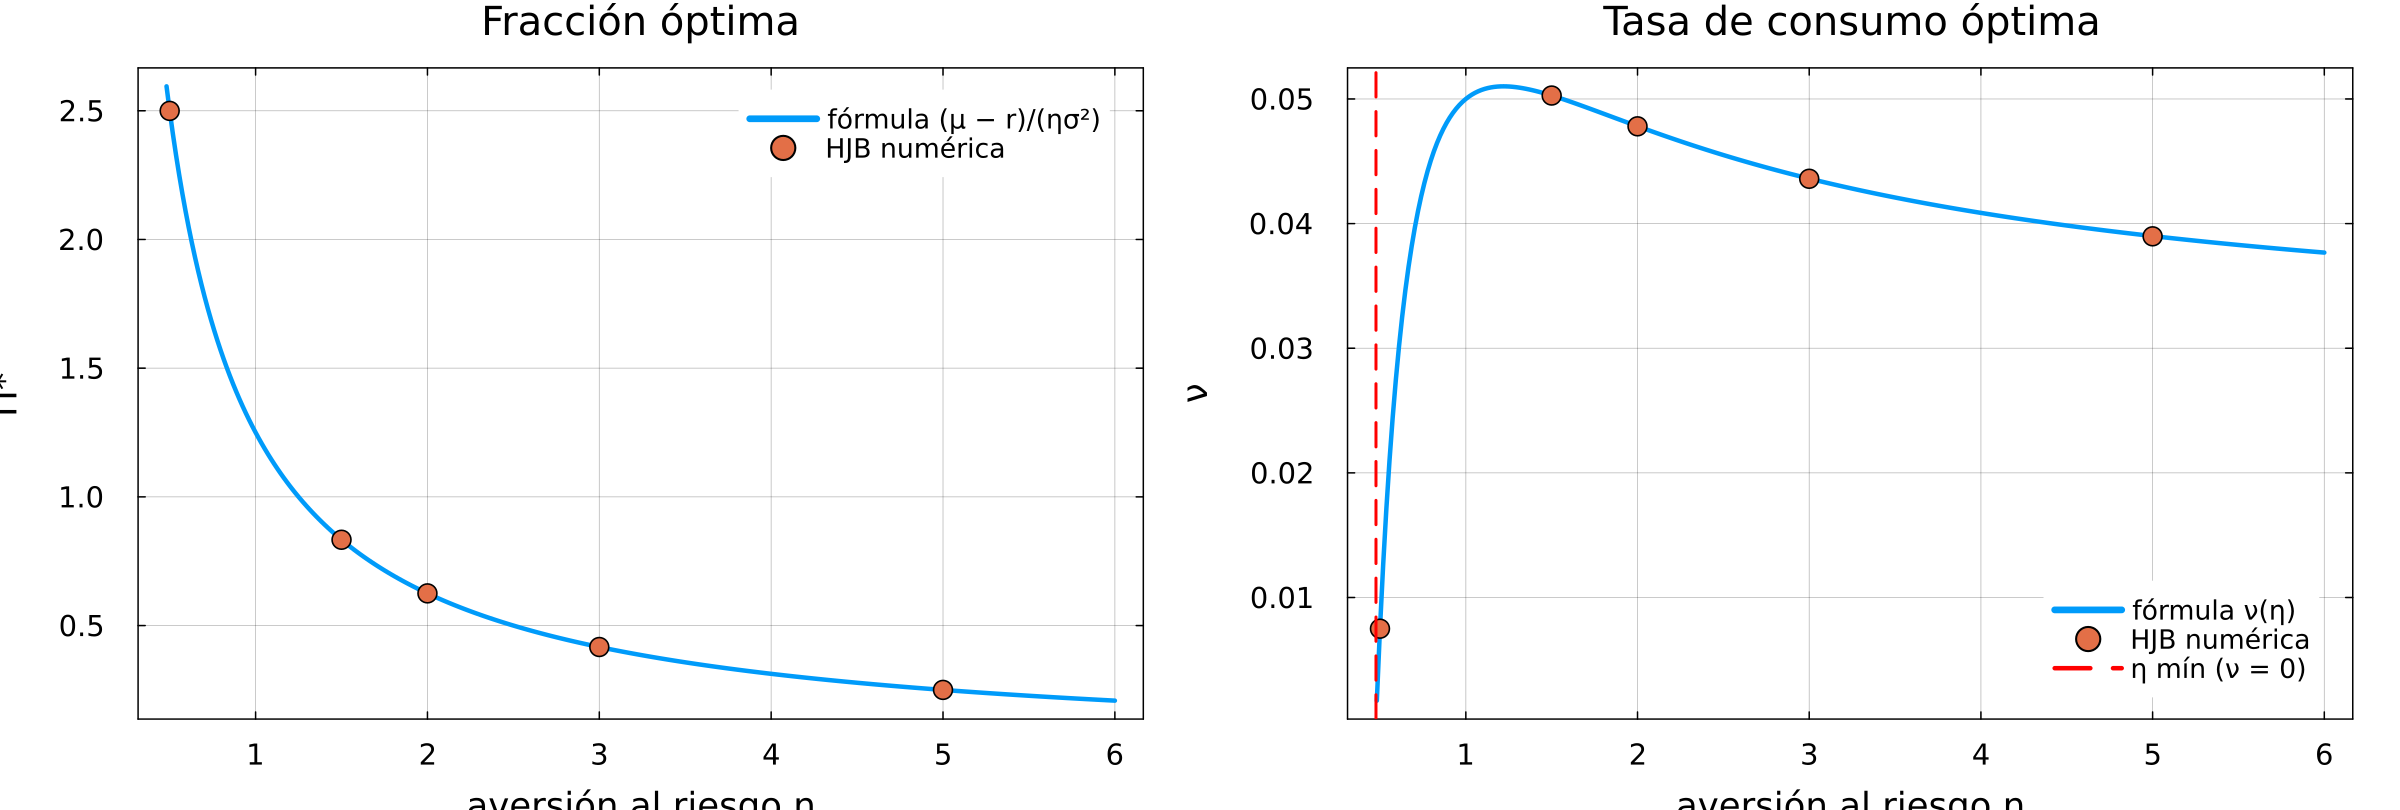

In [8]:
eg = range(eta_min + 0.005, 6, length=300)
q1 = plot(eg, [Pistar(merge(par, (eta = e_,))) for e_ in eg], label="fórmula (μ − r)/(ησ²)",
          xlabel="aversión al riesgo η", ylabel="Π*", title="Fracción óptima")
scatter!(q1, etas, first.(res_eta), label="HJB numérica")
q2 = plot(eg, nu_eta.(eg), label="fórmula ν(η)", xlabel="aversión al riesgo η", ylabel="ν", title="Tasa de consumo óptima",
          legend=:bottomright)
scatter!(q2, etas, last.(res_eta), label="HJB numérica")
vline!(q2, [eta_min], ls=:dash, color=:red, lw=2, label="η mín (ν = 0)")
savefig(plot(q1, dpi=300), "figuras_poster/hjb_fraccion_eta.png")
savefig(plot(q2, dpi=300), "figuras_poster/hjb_consumo_eta.png")
plot(q1, q2, layout=(1, 2), size=(1600, 540))

La sucesión de Howard es creciente, como dice la Proposición 2: la política inicial (banco y consumir los intereses) vale lo mismo que tener 65.6 de capital con Merton, tras una mejora se llega a 96.2 y en tres iteraciones a 99.9. El valor límite queda bajo el exacto solo por el error de malla.

Para todos los $\eta>\eta_{\min}\approx0.477$ probados, la HJB numérica coincide con las fórmulas. La fracción óptima cae como $1/\eta$, y la tasa de consumo no es monótona: es máxima cerca de $\eta=1$, y para $\eta<1$ el inversionista consume poco porque prefiere dejar crecer el capital invertido. Cuando $\eta\to\eta_{\min}$, $\nu\to0$: el inversionista posterga el consumo indefinidamente, y para $\eta\le\eta_{\min}$ el valor es infinito y **no existe** control óptimo. La condición $\nu>0$ del teorema de existencia no es solo técnica.

## 6. Controles admisibles restringidos (objetivo 6)

### 6.1 Fracción acotada

Ross [R, 2.7] pide $|\Pi_t|\le K_\Pi$, y también es natural prohibir el apalancamiento y la venta corta, $0\le\Pi_t\le1$. Consideramos $\Pi_t\in[\Pi_{\min},\Pi_{\max}]$.

**Proposición 3.** Sean $\rho(p)=r+(\mu-r)p-\frac\eta2\sigma^2p^2$ y $\bar p=\mathrm{proy}_{[\Pi_{\min},\Pi_{\max}]}(\Pi^*)$. Si $\nu(\bar p):=\frac{\gamma+(\eta-1)\rho(\bar p)}{\eta}>0$, el control óptimo en la clase restringida es $\Pi_t\equiv\bar p$, $C_t=\nu(\bar p)X_t$, con valor
$$
V_{\bar p}(x)=\frac{1}{1-\eta}\Big(\nu(\bar p)^{-\eta}x^{1-\eta}-\frac1\gamma\Big).
$$
En particular, si $\Pi^*\in[\Pi_{\min},\Pi_{\max}]$ la restricción no cambia nada.

*Demostración.* La Prop. 1 sigue valiendo con la restricción, así que $V$ es de la forma $\frac{A}{1-\eta}x^{1-\eta}-\frac{1}{(1-\eta)\gamma}$. Al reemplazar en la HJB, el término que depende de $\Pi$ es $Ax^{1-\eta}\big[\Pi(\mu-r)-\frac\eta2\sigma^2\Pi^2\big]$, una parábola cóncava cuyo máximo sobre el intervalo es la proyección del vértice $\Pi^*$. Con $\Pi=\bar p$, la ecuación para $A$ es la del caso sin restricción con $r+\frac{\theta^2}{2\eta}=\rho(\Pi^*)$ reemplazado por $\rho(\bar p)$, y da $A=\nu(\bar p)^{-\eta}$. La verificación es la misma del reporte. $\blacksquare$

Equivalentemente, $V_{\bar p}(x)=J(x;\bar p,\nu(\bar p))$ con la Prop. 2 del avance 2, y $\nu(\bar p)$ es la tasa de consumo que maximiza $J(x;\bar p,\cdot)$. Comprobamos la proposición con el mismo solver, cambiando solo las cotas de $\Pi$.

In [9]:
rho(p; P=par) = P.r + (P.mu - P.r)*p - 0.5*P.eta*P.sigma^2*p^2
nu_p(p; P=par) = (P.gamma + (P.eta - 1)*rho(p; P=P))/P.eta

y = collect(range(log(1.0), log(1e4), length=801)); i0 = 401
cotas = [("sin restricción",           -5.0, 5.0), ("|Pi| <= 1 (Ross, K = 1)", -1.0, 1.0),
         ("0 <= Pi <= 0.5",             0.0, 0.5), ("0 <= Pi <= 0.25",          0.0, 0.25),
         ("Pi >= 1 (mínimo en acción)", 1.0, 5.0), ("solo banco, Pi = 0",       0.0, 0.0)]
@printf("%-28s %7s %7s %9s %9s %9s %9s %7s\n", "restricción", "Pi HJB", "p", "e HJB", "nu(p)", "W(x0)", "V_p(x0)", "xCE")
for (nombre, lo, hi) in cotas
    s = resolver_hjb(y; Pimin=lo, Pimax=hi)
    p = clamp(Pistar(), lo, hi)
    Vp = Jexacto(p, nu_p(p))
    @printf("%-28s %7.4f %7.4f %9.5f %9.5f %9.4f %9.4f %7.2f\n", nombre, s.Pi[i0], p, s.e[i0], nu_p(p), s.W[i0], Vp, xCE(Vp))
end

restricción                   Pi HJB       p     e HJB     nu(p)     W(x0)   V_p(x0)     xCE
sin restricción               0.6250  0.6250   0.04780   0.04781   15.6226   15.6256  100.00
|Pi| <= 1 (Ross, K = 1)       0.6250  0.6250   0.04780   0.04781   15.6226   15.6256  100.00
0 <= Pi <= 0.5                0.5000  0.5000   0.04749   0.04750   15.5665   15.5679   98.70
0 <= Pi <= 0.25               0.2500  0.2500   0.04499   0.04500   15.0594   15.0617   88.58
Pi >= 1 (mínimo en acción)    1.0000  1.0000   0.04496   0.04500   15.0523   15.0617   88.58
solo banco, Pi = 0            0.0000  0.0000   0.03997   0.04000   13.7410   13.7500   69.99


El solver con cotas reproduce la Proposición 3 en todos los casos: la fracción numérica es la proyección de $\Pi^*$, y la tasa de consumo y el valor son los de la fórmula. Tres observaciones:

* Las cotas que contienen a $\Pi^*=0.625$, como $|\Pi|\le1$, no cambian nada: el control de Merton ya era admisible para Ross con cualquier $K_\Pi\ge0.625$, como se dijo en el reporte.
* Con $\eta=2$, $\rho$ es simétrica en torno a $\Pi^*$, así que obligar a $\Pi\ge1$ o a $\Pi\le0.25$ cuesta lo mismo (capital equivalente 88.6): pasarse o quedarse corto por la misma distancia es igual de malo.
* La pérdida es pequeña cerca de $\Pi^*$ ($\Pi\le0.5$ equivale a perder 1.3 de capital) porque $\rho$ es plana en su máximo, y grande lejos de él: no invertir nada equivale a perder 30 de capital.

La restricción también cambia el consumo: con menos rentabilidad, el inversionista con $\eta>1$ consume menos, $\nu(\bar p)<\nu$.

### 6.2 Controles markovianos y no markovianos

Un control es **markoviano** (de retroalimentación) si $\Pi_t=\pi(t,X_t)$ y $C_t=c(t,X_t)$: solo mira el estado actual. Uno **no markoviano** usa la historia, del capital o del precio.

**Proposición 4.** Para todo control admisible de $\mathcal A_K$, markoviano o no, $J(x;\Pi,C)\le V(x)$, y el control markoviano de Merton alcanza la igualdad. Por lo tanto, restringir la clase a controles markovianos, o incluso a estrategias proporcionales de fracción constante, **no cambia el valor**.

*Demostración.* La cota por dualidad del reporte (§1.5) usa solo la desigualdad de Fenchel y la restricción presupuestaria, que valen para todo control de $\mathcal A_K$ sin importar cómo dependa de la historia. El control de Merton es markoviano y alcanza la cota. $\blacksquare$

Al revés, restringir a controles **deterministas** en monto ($\Pi_tX_t=\pi(t)$, $C_t=c(t)$) sí es un problema: con ruido el capital es gaussiano y se vuelve negativo con probabilidad positiva, así que esos controles no son admisibles (avance 1, Obs. 4.2).

**Experimento.** Comparamos con Monte-Carlo, en los mismos escenarios, cinco reglas:

| Regla | Tipo |
| --- | --- |
| Merton: $\Pi^*$, $C=\nu X$ | markoviana, óptima |
| Ingenua: $\Pi=1$, $C=0.04X$ | markoviana |
| Caída desde el máximo: $\Pi_t=\Pi^*X_t/\max_{s\le t}X_s$, $C=\nu X$ | no markoviana: baja la exposición tras una caída del capital |
| Media móvil: $\Pi_t=1$ si $S_t$ supera su promedio del último año y $0$ si no, $C=\nu X$ | no markoviana: mira la historia del precio |
| Merton con $\mu$ estimado: $\Pi_t=\frac{\hat\mu_t-r}{\eta\sigma^2}$ (acotada a $[0,2]$), $\hat\mu_t=\frac{\log S_t}{t}+\frac{\sigma^2}2$, desde el año 1 | no markoviana: aprende $\mu$ de los precios (ver el avance 3) |

Cada regla se aplica hasta $T=30$ años y después se sigue con Merton, así que el estimador es el del avance 2 con valor de continuación $V(X_T)$:
$$
Y=\sum_kw_k\,e^{-\gamma t_k}U(C_{t_k})+e^{-\gamma T}V(X_T),\qquad \mathbb E[Y]\le V(x_0),
$$
porque "la regla hasta $T$ y Merton después" es un control admisible. El capital se simula con el esquema log-Euler congelando el control en cada paso semanal, que es exacto para el control congelado.

In [10]:
# precio de la acción (S_0 = 1) en los mismos escenarios Z; filas = tiempos t_k = (k-1) h
function simular_precio(Z, h; P=par)
    logS = cumsum((P.mu - P.sigma^2/2)*h .+ P.sigma*sqrt(h) .* Z, dims=1)
    return vcat(ones(1, size(Z, 2)), exp.(logS))
end

# Y = utilidad descontada hasta T (trapecio) + e^{-gamma T} V(X_T), para una regla (Pi, e) = regla(k, X, Xmax)
# que se decide al inicio de cada paso con la información disponible y se congela durante el paso
function utilidad_regla(regla, Z, h; P=par)
    K, N = size(Z)
    X = fill(P.x0, N); Xmax = copy(X); Y = zeros(N)
    for k in 1:K
        Pi, e = regla(k, X, Xmax)
        Y .+= (k == 1 ? h/2 : h)*exp(-P.gamma*(k - 1)*h) .* U.(e .* X; P=P)
        X .*= exp.((P.r .+ Pi .* (P.mu - P.r) .- e .- 0.5*P.sigma^2 .* Pi.^2) .* h .+ P.sigma .* Pi .* sqrt(h) .* Z[k, :])
        Xmax .= max.(Xmax, X)
    end
    Pi, e = regla(K + 1, X, Xmax)
    return Y .+ (h/2)*exp(-P.gamma*K*h) .* U.(e .* X; P=P) .+ exp(-P.gamma*K*h) .* V.(X; P=P)
end

utilidad_regla (generic function with 1 method)

In [11]:
Random.seed!(20)
T, h, N = 30.0, 1/52, 5_000
K = round(Int, T/h)
Z = randn(K, N)
S = simular_precio(Z, h)
uno, nuN = ones(N), fill(nustar(), N)

media_movil(k) = Float64.(S[k, :] .> vec(mean(view(S, max(1, k - 52):k, :), dims=1)))
pi_estimado(k) = k <= 53 ? zeros(N) : clamp.((log.(S[k, :]) ./ ((k - 1)*h) .+ par.sigma^2/2 .- par.r) ./ (par.eta*par.sigma^2), 0.0, 2.0)

reglas = ["Merton (markoviana, óptima)"  => (k, X, Xmax) -> (Pistar() .* uno, nuN),
          "Ingenua: Pi = 1, C = 0.04X"   => (k, X, Xmax) -> (uno, 0.04 .* uno),
          "Caída desde el máximo"        => (k, X, Xmax) -> (Pistar() .* X ./ Xmax, nuN),
          "Media móvil de 1 año"         => (k, X, Xmax) -> (media_movil(k), nuN),
          "Merton con mu estimado"       => (k, X, Xmax) -> (pi_estimado(k), nuN)]

res = Dict{String, Vector{Float64}}()
@printf("%-30s %10s %8s %8s\n", "regla", "J_N (MC)", "+-IC95", "xCE")
for (nombre, regla) in reglas
    Y = utilidad_regla(regla, Z, h)
    res[nombre] = Y
    @printf("%-30s %10.4f %8.4f %8.2f\n", nombre, mean(Y), 1.96*std(Y)/sqrt(N), xCE(mean(Y)))
end
@printf("%-30s %10.4f\n\n", "V(x0) exacto", V(par.x0))

YM = res["Merton (markoviana, óptima)"]
@printf("%-30s %12s %10s\n", "regla", "J_M - J", "+-IC95 pareado")
for (nombre, _) in reglas[2:end]
    d = YM .- res[nombre]
    @printf("%-30s %12.4f %10.4f\n", nombre, mean(d), 1.96*std(d)/sqrt(N))
end

regla                            J_N (MC)   +-IC95      xCE
Merton (markoviana, óptima)       15.6225   0.0524    99.93
Ingenua: Pi = 1, C = 0.04X        15.1178   0.1019    89.60
Caída desde el máximo             15.5328   0.0415    97.92
Media móvil de 1 año              14.8063   0.0802    84.22
Merton con mu estimado            14.6525   0.0641    81.80
V(x0) exacto                      15.6256

regla                               J_M - J +-IC95 pareado
Ingenua: Pi = 1, C = 0.04X           0.5047     0.0528
Caída desde el máximo                0.0897     0.0170
Media móvil de 1 año                 0.8163     0.0577
Merton con mu estimado               0.9700     0.0531


Ninguna regla supera a $V(x_0)$ y la de Merton lo alcanza dentro del intervalo de confianza, como dice la Proposición 4. Las comparaciones pareadas muestran con significancia que todas las demás son peores:

* **Caída desde el máximo** pierde poco (capital equivalente 97.9): reducir la exposición tras una caída aleja la fracción de $\Pi^*$ justo cuando el capital es bajo. Mirar la historia del capital no ayuda, porque el futuro de la acción no depende de ella.
* **Media móvil** pierde más (84.2): el precio es un movimiento browniano geométrico, sin tendencias que la regla pueda aprovechar, y la regla solo agrega cambios bruscos entre $\Pi=0$ y $\Pi=1$.
* **Merton con $\mu$ estimado** es la peor (81.8): en los primeros años el estimador de $\mu$ es tan ruidoso que la fracción estimada se aleja mucho de $\Pi^*$. Esta regla representa a un inversionista que no conoce $\mu$, y su pérdida es el costo de no conocerlo (avance 3).

Conclusión: restringirse a controles markovianos no pierde nada. La historia solo sirve cuando hay algo que aprender de ella, como un parámetro desconocido.

## 7. Conclusiones y pendientes

**Conclusiones.**
1. La HJB se resuelve numéricamente con un esquema *upwind* monótono e iteración de políticas, con una condición de borde que sale de la homotecia y no necesita conocer $V$. El método converge con orden 1 y reproduce $\Pi^*$, $\nu$ y $V$ (objetivo 5).
2. La iteración de políticas construye controles markovianos admisibles cuyo valor crece hasta $V$, y la condición $\nu>0$ separa los casos con y sin control óptimo: con nuestros parámetros, $\eta>\eta_{\min}\approx0.477$ (objetivo 4).
3. Con la fracción acotada, el óptimo es la proyección de $\Pi^*$ con su propia tasa de consumo $\nu(\bar p)$. Restringir a controles markovianos no pierde valor, y las reglas que miran la historia sin tener nada que aprender son peores (objetivo 6).

**Pendientes.**
* Demostrar la convergencia del esquema a la solución de viscosidad de la HJB (teorema de Barles–Souganidis: monotonía, estabilidad y consistencia); aquí solo la verificamos numéricamente.
* Subir el orden de convergencia sin perder la monotonía, por ejemplo con mallas no uniformes o diferencias centradas donde la difusión domina a la deriva.

El mismo solver se usa en el avance 5 para un problema sin solución explícita (tiempo de parada con piso).